# 05. Tabular Neural Network (MLP Regressor)
Triển khai Mạng Nơ-ron `MLPRegressor` 2 tầng ẩn: `hidden_layer_sizes=(64, 32)`, hàm kích hoạt `relu`, `StandardScaler` (chỉ fit trên Train).


In [1]:
import os
import time
import json
import joblib
import warnings
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

BASE_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed")
if not os.path.exists(PROCESSED_DIR):
    PROCESSED_DIR = os.path.join(BASE_DIR, "data_processed")
ARTIFACTS_DIR = os.path.join(BASE_DIR, "artifacts")

def load_data(scenario):
    p_train = os.path.join(PROCESSED_DIR, f"dataset_{scenario}_train.parquet")
    p_val = os.path.join(PROCESSED_DIR, f"dataset_{scenario}_val.parquet")
    p_test = os.path.join(PROCESSED_DIR, f"dataset_{scenario}_test.parquet")
    if os.path.exists(p_train):
        return pd.read_parquet(p_train), pd.read_parquet(p_val), pd.read_parquet(p_test)
    return pd.read_csv(p_train.replace(".parquet", ".csv")), pd.read_csv(p_val.replace(".parquet", ".csv")), pd.read_csv(p_test.replace(".parquet", ".csv"))

def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    
    act_150 = (y_true > 150)
    pred_150 = (y_pred > 150)
    tp_150 = np.sum(act_150 & pred_150)
    recall_150 = tp_150 / (np.sum(act_150) + 1e-8)
    prec_150 = tp_150 / (np.sum(pred_150) + 1e-8)
    f1_150 = 2 * prec_150 * recall_150 / (prec_150 + recall_150 + 1e-8)
    return {
        "R2": float(r2), "MAE": float(mae), "RMSE": float(rmse),
        "sMAPE": float(smape), "Recall_150": float(recall_150),
        "Precision_150": float(prec_150), "F1_150": float(f1_150)
    }


### Huấn Luyện MLPRegressor


In [2]:
mlp_results = []

for sc in ["1h", "24h"]:
    print(f"--- Huấn luyện MLP: {sc.upper()} ---")
    train_df, val_df, test_df = load_data(sc)
    feat_cols = [c for c in train_df.columns if c not in ['time', 'year', 'target']]
    
    X_train = pd.get_dummies(train_df[feat_cols], columns=['station_id'], drop_first=True)
    X_val = pd.get_dummies(val_df[feat_cols], columns=['station_id'], drop_first=True).reindex(columns=X_train.columns, fill_value=0)
    X_test = pd.get_dummies(test_df[feat_cols], columns=['station_id'], drop_first=True).reindex(columns=X_train.columns, fill_value=0)
    
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s = scaler.transform(X_val)
    X_test_s = scaler.transform(X_test)
    
    y_train = train_df['target'].values
    y_val = val_df['target'].values
    y_test = test_df['target'].values
    
    t0 = time.time()
    mlp = MLPRegressor(
        hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
        alpha=0.01, batch_size=128, learning_rate_init=0.003,
        max_iter=120, early_stopping=True, validation_fraction=0.1,
        random_state=42
    )
    mlp.fit(X_train_s, y_train)
    time_mlp = time.time() - t0
    
    val_pred = mlp.predict(X_val_s)
    test_pred = mlp.predict(X_test_s)
    
    m_val = calculate_metrics(y_val, val_pred)
    m_test = calculate_metrics(y_test, test_pred)
    
    joblib.dump(mlp, f"{ARTIFACTS_DIR}/models/model_mlp_{sc}.joblib")
    joblib.dump(scaler, f"{ARTIFACTS_DIR}/models/scaler_mlp_{sc}.joblib")
    
    pred_df = test_df[['time', 'station_id', 'target']].copy().rename(columns={'target': 'actual'})
    pred_df['pred_mlp'] = test_pred
    pred_df.to_csv(f"{ARTIFACTS_DIR}/predictions/preds_{sc}_mlp.csv", index=False)
    
    mlp_results.append({
        "scenario": sc, "family": "Neural Network", "model": "MLP (64, 32)",
        "val_R2_2024": m_val["R2"], "val_MAE_2024": m_val["MAE"],
        "test_R2_2025": m_test["R2"], "test_MAE_2025": m_test["MAE"],
        "test_RMSE_2025": m_test["RMSE"], "test_sMAPE_2025": m_test["sMAPE"],
        "test_F1_150": m_test["F1_150"], "time_sec": time_mlp
    })
    print(f"MLP {sc} ({time_mlp:.1f}s): Test R2 = {m_test['R2']:.4f}, Test MAE = {m_test['MAE']:.2f}")

df_mlp_res = pd.DataFrame(mlp_results)
df_mlp_res.to_json(f"{ARTIFACTS_DIR}/metrics/metrics_mlp.json", orient="records", indent=2)
df_mlp_res[['scenario', 'model', 'val_R2_2024', 'test_R2_2025', 'test_MAE_2025', 'test_RMSE_2025', 'time_sec']]


--- Huấn luyện MLP: 1H ---
MLP 1h (10.3s): Test R2 = 0.9583, Test MAE = 3.26
--- Huấn luyện MLP: 24H ---
MLP 24h (73.1s): Test R2 = 0.5011, Test MAE = 13.08


,scenario,model,val_R2_2024,test_R2_2025,test_MAE_2025,test_RMSE_2025,time_sec
0,1h,"MLP (64, 32)",0.905833,0.958289,3.257183,5.408014,10.285127
1,24h,"MLP (64, 32)",0.418627,0.501132,13.076733,18.655680,73.095085


### 3. Trực quan hóa Đường cong Huấn luyện (Training Loss và Validation Curves)
Trích xuất thuộc tính `loss_curve_` và `validation_scores_` từ 2 mô hình MLP đã lưu để phân tích động lực hội tụ và cơ chế dừng sớm (Early Stopping).


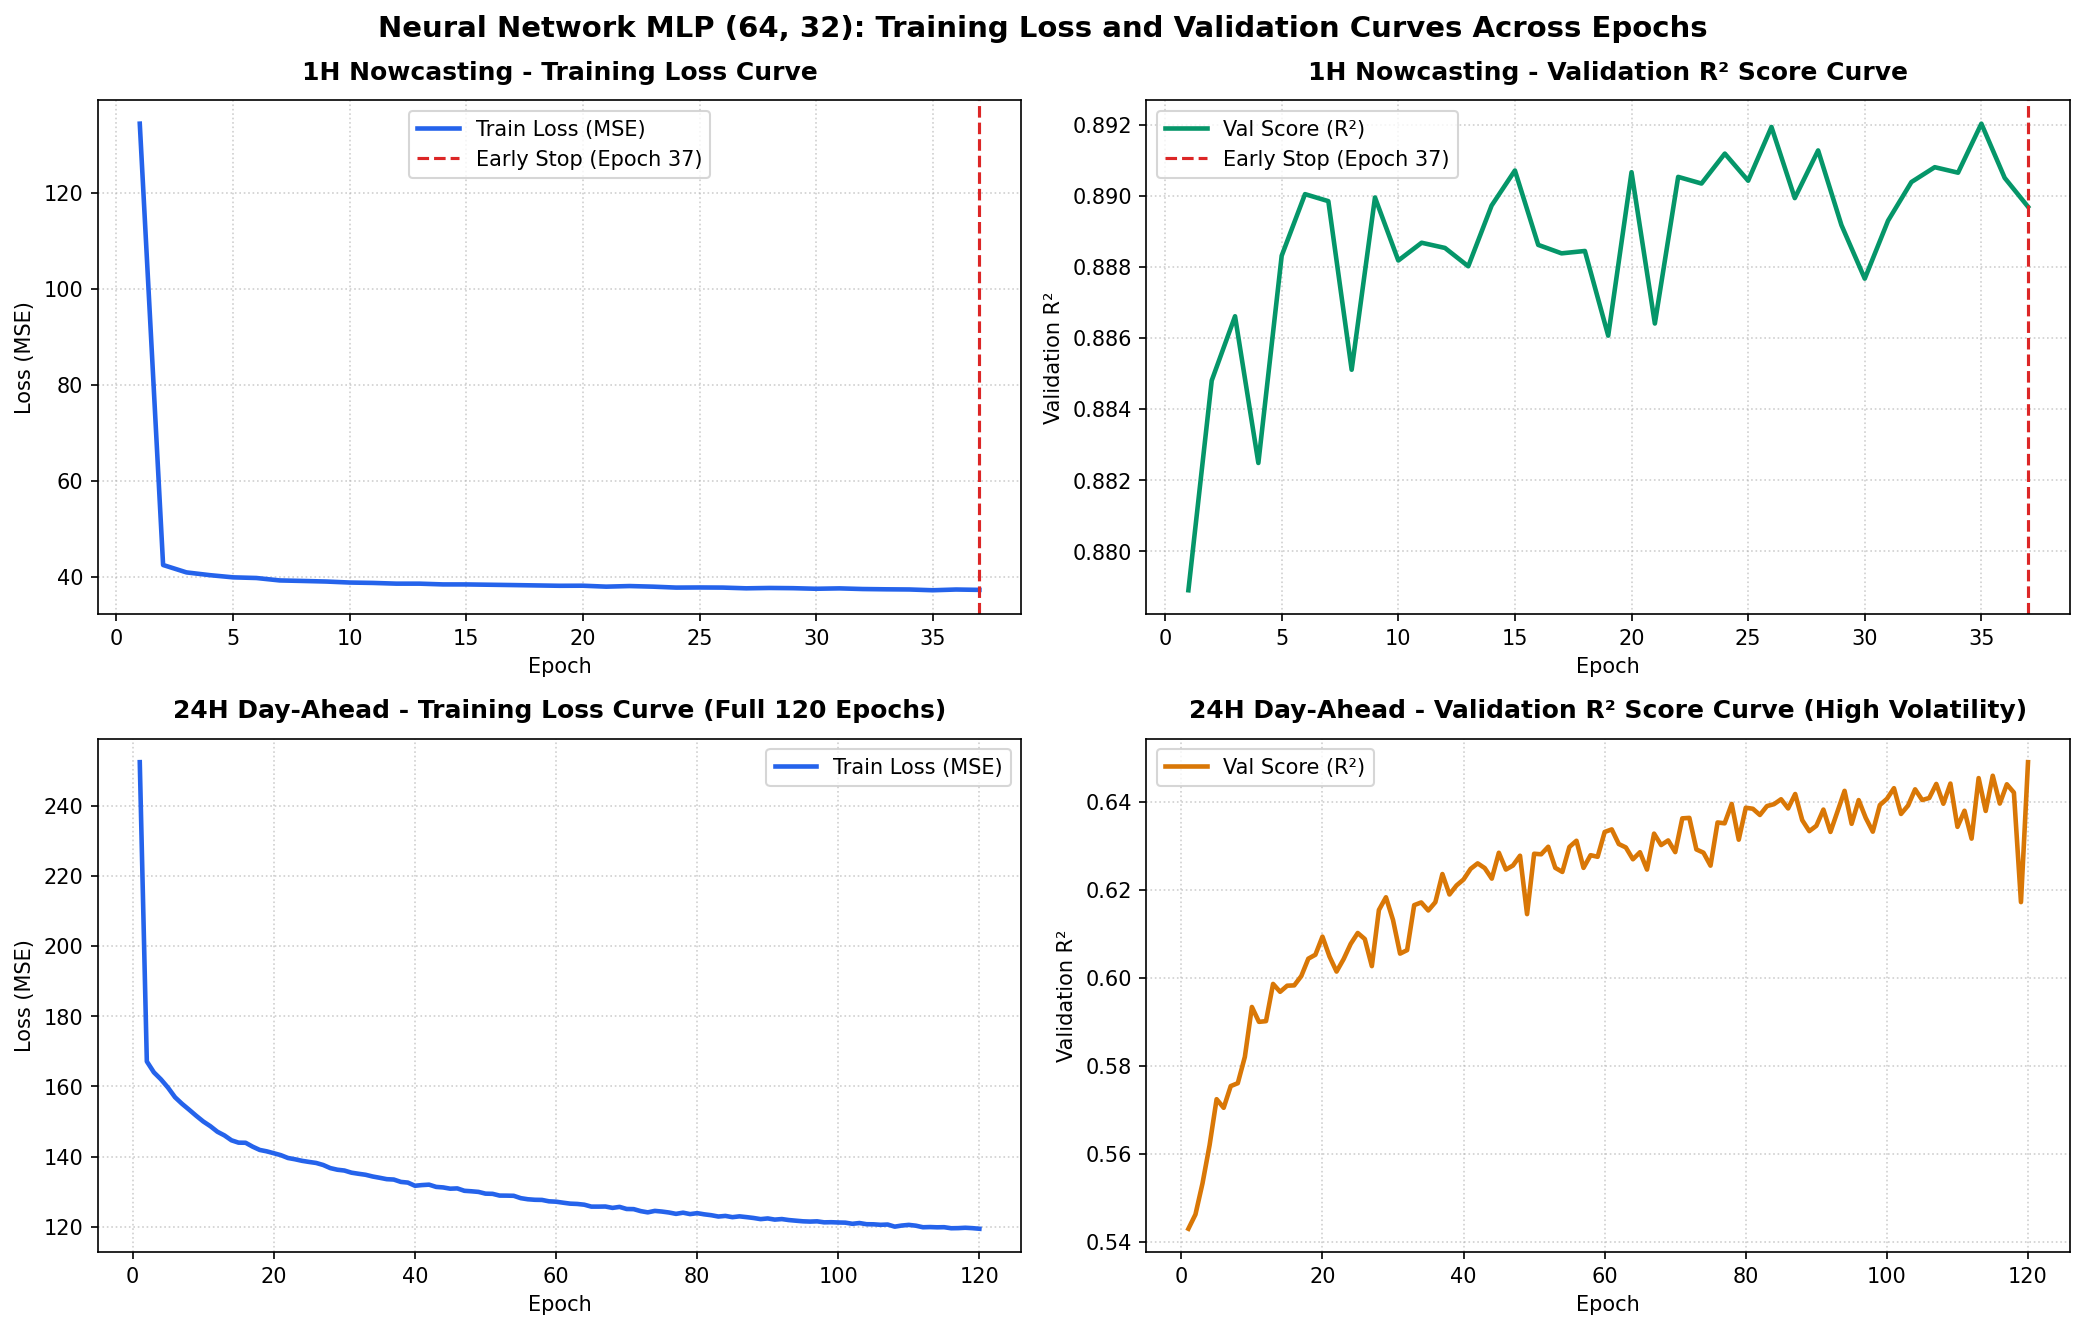

In [3]:
import matplotlib.pyplot as plt

m1 = joblib.load(f"{ARTIFACTS_DIR}/models/model_mlp_1h.joblib")
m24 = joblib.load(f"{ARTIFACTS_DIR}/models/model_mlp_24h.joblib")

fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=150)
fig.patch.set_facecolor("#ffffff")

# 1H Loss
axes[0, 0].plot(range(1, len(m1.loss_curve_)+1), m1.loss_curve_, color="#2563eb", lw=2.2, label="Train Loss (MSE)")
axes[0, 0].axvline(len(m1.loss_curve_), color="#dc2626", linestyle="--", lw=1.5, label=f"Early Stop (Epoch {len(m1.loss_curve_)})")
axes[0, 0].set_title("1H Nowcasting - Training Loss Curve", fontsize=12, fontweight="bold", pad=10)
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss (MSE)")
axes[0, 0].grid(True, linestyle=":", alpha=0.6)
axes[0, 0].legend()

# 1H Val R2
axes[0, 1].plot(range(1, len(m1.validation_scores_)+1), m1.validation_scores_, color="#059669", lw=2.2, label="Val Score (R²)")
axes[0, 1].axvline(len(m1.validation_scores_), color="#dc2626", linestyle="--", lw=1.5, label=f"Early Stop (Epoch {len(m1.validation_scores_)})")
axes[0, 1].set_title("1H Nowcasting - Validation R² Score Curve", fontsize=12, fontweight="bold", pad=10)
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Validation R²")
axes[0, 1].grid(True, linestyle=":", alpha=0.6)
axes[0, 1].legend()

# 24H Loss
axes[1, 0].plot(range(1, len(m24.loss_curve_)+1), m24.loss_curve_, color="#2563eb", lw=2.2, label="Train Loss (MSE)")
axes[1, 0].set_title(f"24H Day-Ahead - Training Loss Curve (Full {len(m24.loss_curve_)} Epochs)", fontsize=12, fontweight="bold", pad=10)
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Loss (MSE)")
axes[1, 0].grid(True, linestyle=":", alpha=0.6)
axes[1, 0].legend()

# 24H Val R2
axes[1, 1].plot(range(1, len(m24.validation_scores_)+1), m24.validation_scores_, color="#d97706", lw=2.2, label="Val Score (R²)")
axes[1, 1].set_title("24H Day-Ahead - Validation R² Score Curve (High Volatility)", fontsize=12, fontweight="bold", pad=10)
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Validation R²")
axes[1, 1].grid(True, linestyle=":", alpha=0.6)
axes[1, 1].legend()

plt.suptitle("Neural Network MLP (64, 32): Training Loss and Validation Curves Across Epochs", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(f"{ARTIFACTS_DIR}/figures/mlp_learning_curves.png", bbox_inches="tight")
plt.show()
